In [2]:
from pathlib import Path
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors

# Locate project folder
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_dir = project_dir / "data"
docking_dir = project_dir / "docking"
results_dir = project_dir / "results"
figures_dir = project_dir / "figures"

for folder in [data_dir, docking_dir, results_dir, figures_dir]:
    folder.mkdir(exist_ok=True)

print("PCOS screening project ready!")

PCOS screening project ready!


Final candidate dataset

In [3]:
import pandas as pd
from pathlib import Path

project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_dir = project_dir / "data"
data_dir.mkdir(exist_ok=True)

# Five selected compounds for PCOS-related drug screening
compounds = [
    {"Compound": "Empagliflozin", "Category": "SGLT2 inhibitor"},
    {"Compound": "Pioglitazone", "Category": "PPAR-gamma agonist"},
    {"Compound": "Sitagliptin", "Category": "DPP-4 inhibitor"},
    {"Compound": "Orlistat", "Category": "Lipase inhibitor"},
    {"Compound": "Berberine", "Category": "Natural-product alkaloid"}
]

candidates_df = pd.DataFrame(compounds)

display(candidates_df)

# Save your dataset
candidates_df.to_csv(
    data_dir / "PCOS_drug_candidates.csv",
    index=False
)

print("Five PCOS candidate compounds saved!")

,Compound,Category
0,Empagliflozin,SGLT2 inhibitor
1,Pioglitazone,PPAR-gamma agonist
2,Sitagliptin,DPP-4 inhibitor
3,Orlistat,Lipase inhibitor
4,Berberine,Natural-product alkaloid


Five PCOS candidate compounds saved!


In [4]:
from pathlib import Path
import requests
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors

# Find project folder
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_dir = project_dir / "data"
docking_dir = project_dir / "docking"
results_dir = project_dir / "results"

ligand_dir = docking_dir / "candidate_ligands"

for folder in [data_dir, docking_dir, results_dir, ligand_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# Your selected compounds
compounds = [
    "Empagliflozin",
    "Pioglitazone",
    "Sitagliptin",
    "Orlistat",
    "Berberine"
]

print("Project ready!")
print("Compounds to prepare:", len(compounds))

Project ready!
Compounds to prepare: 5


In [5]:
from urllib.parse import quote

compound_records = []

for name in compounds:
    url = (
        "https://pubchem.ncbi.nlm.nih.gov/rest/pug/"
        f"compound/name/{quote(name)}/"
        "property/SMILES,MolecularFormula,MolecularWeight/JSON"
    )

    try:
        response = requests.get(url, timeout=45)
        response.raise_for_status()

        properties = response.json()["PropertyTable"]["Properties"][0]

        compound_records.append({
            "Compound": name,
            "PubChem_CID": properties["CID"],
            "SMILES": properties["SMILES"],
            "Molecular_Formula": properties["MolecularFormula"],
            "Molecular_Weight": float(properties["MolecularWeight"])
        })

        print(f"Downloaded information for {name}")

    except Exception as e:
        print(f"Failed for {name}: {e}")

compound_df = pd.DataFrame(compound_records)

display(compound_df)

Downloaded information for Empagliflozin
Downloaded information for Pioglitazone
Downloaded information for Sitagliptin
Downloaded information for Orlistat
Downloaded information for Berberine


,Compound,PubChem_CID,SMILES,Molecular_Formula,Molecular_Weight
0,Empagliflozin,11949646,C1COC[C@H]1OC2=CC=C(C=C2)CC3=C(C=CC(=C3)[C@H]4...,C23H27ClO7,450.90
1,Pioglitazone,4829,CCC1=CN=C(C=C1)CCOC2=CC=C(C=C2)CC3C(=O)NC(=O)S3,C19H20N2O3S,356.40
2,Sitagliptin,4369359,C1CN2C(=NN=C2C(F)(F)F)CN1C(=O)C[C@@H](CC3=CC(=...,C16H15F6N5O,407.31
3,Orlistat,3034010,CCCCCCCCCCC[C@@H](C[C@H]1[C@@H](C(=O)O1)CCCCCC...,C29H53NO5,495.70
4,Berberine,2353,COC1=C(C2=C[N+]3=C(C=C2C=C1)C4=CC5=C(C=C4CC3)O...,C20H18NO4+,336.40


In [6]:
from rdkit.Chem import AllChem

if len(compound_df) != 5:
    raise ValueError("All five compounds must be retrieved first.")

prepared_records = []

for _, row in compound_df.iterrows():
    name = row["Compound"]
    smiles = row["SMILES"]

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        print(f"Invalid SMILES: {name}")
        continue

    # Add explicit hydrogens
    mol = Chem.AddHs(mol)

    # Generate a reproducible 3D conformer
    params = AllChem.ETKDGv3()
    params.randomSeed = 42
    params.maxIterations = 1000

    result = AllChem.EmbedMolecule(mol, params)

    if result != 0:
        print(f"3D generation failed: {name}")
        continue

    # Optimize geometry with MMFF when supported
    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol, maxIters=500)

    # Save as SDF
    sdf_path = ligand_dir / f"{name.lower()}_3d.sdf"

    writer = Chem.SDWriter(str(sdf_path))
    writer.write(mol)
    writer.close()

    prepared_records.append({
        "Compound": name,
        "PubChem_CID": row["PubChem_CID"],
        "SDF_File": str(sdf_path),
        "Atoms": mol.GetNumAtoms(),
        "3D": mol.GetConformer().Is3D()
    })

    print(f"Prepared 3D structure: {name}")

prepared_df = pd.DataFrame(prepared_records)

display(prepared_df)

Prepared 3D structure: Empagliflozin
Prepared 3D structure: Pioglitazone
Prepared 3D structure: Sitagliptin
Prepared 3D structure: Orlistat
Prepared 3D structure: Berberine


,Compound,PubChem_CID,SDF_File,Atoms,3D
0,Empagliflozin,11949646,/Users/tavimangoma/PCOS_Drug_Repurposing/docki...,58,True
1,Pioglitazone,4829,/Users/tavimangoma/PCOS_Drug_Repurposing/docki...,45,True
2,Sitagliptin,4369359,/Users/tavimangoma/PCOS_Drug_Repurposing/docki...,43,True
3,Orlistat,3034010,/Users/tavimangoma/PCOS_Drug_Repurposing/docki...,88,True
4,Berberine,2353,/Users/tavimangoma/PCOS_Drug_Repurposing/docki...,43,True


In [7]:
# Confirm all five compounds have docking files

for drug in compounds:
    file_path = ligand_dir / f"{drug.lower()}.pdbqt"

    print(
        drug,
        "Ready for docking:",
        file_path.exists()
    )

Empagliflozin Ready for docking: True
Pioglitazone Ready for docking: True
Sitagliptin Ready for docking: True
Orlistat Ready for docking: True
Berberine Ready for docking: True


In [8]:

from vina import Vina
import pandas as pd

# Initialize Vina
v = Vina(sf_name="vina", cpu=4, seed=42)

# Load your prepared PTP1B receptor
receptor_path = docking_dir / "PTP1B_receptor.pdbqt"
v.set_receptor(str(receptor_path))

# Set the same binding pocket for all compounds
v.compute_vina_maps(
    center=[33.68, 28.42, 20.58],
    box_size=[24, 24, 24]
)

# Store docking results
screening_results = []

for drug in compounds:

    print(f"\nDocking {drug}...")

    ligand_path = ligand_dir / f"{drug.lower()}.pdbqt"

    # Load candidate ligand
    v.set_ligand_from_file(str(ligand_path))

    # Perform molecular docking
    v.dock(exhaustiveness=16, n_poses=10)

    # Retrieve predicted energies
    energies = v.energies()

    # Save predicted poses
    output_path = ligand_dir / f"{drug.lower()}_docked.pdbqt"

    v.write_poses(
        str(output_path),
        n_poses=10,
        overwrite=True
    )

    # Record the best score
    best_energy = float(energies[0, 0])

    screening_results.append({
        "Compound": drug,
        "Best_Binding_Energy_kcal_mol": best_energy,
        "Number_of_Poses": len(energies)
    })

    print(f"Best docking score: {best_energy:.3f} kcal/mol")

print("\nAll docking experiments completed!")


Computing Vina grid ... 
Docking Empagliflozin...
done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -7.535          0          0
   2       -7.529      6.697      10.62
   3       -7.503      4.304      10.15
   4        -7.32      1.817      2.994
   5       -7.207      1.787      2.687
   6       -7.183      3.349      4.278
   7       -7.149      2.378       3.74
   8       -7.095      4.382      6.575
   9       -7.084      1.215      1.736
  10       -6.938      3.117      4.423
Best docking score: -7.535 kcal/mol

Docking Pioglitazone...
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
**********

In [9]:

# Convert results into a DataFrame
screening_df = pd.DataFrame(screening_results)

# Rank compounds by their best docking score
screening_df = screening_df.sort_values(
    "Best_Binding_Energy_kcal_mol"
).reset_index(drop=True)

screening_df["Rank"] = range(1, len(screening_df) + 1)

display(screening_df)

# Save the results
output_file = results_dir / "PCOS_docking_results.csv"
screening_df.to_csv(output_file, index=False)

print("Results saved successfully!")


,Compound,Best_Binding_Energy_kcal_mol,Number_of_Poses,Rank
0,Empagliflozin,-7.535,9,1
1,Sitagliptin,-7.432,9,2
2,Berberine,-7.104,9,3
3,Pioglitazone,-6.627,9,4
4,Orlistat,-6.026,9,5


Results saved successfully!


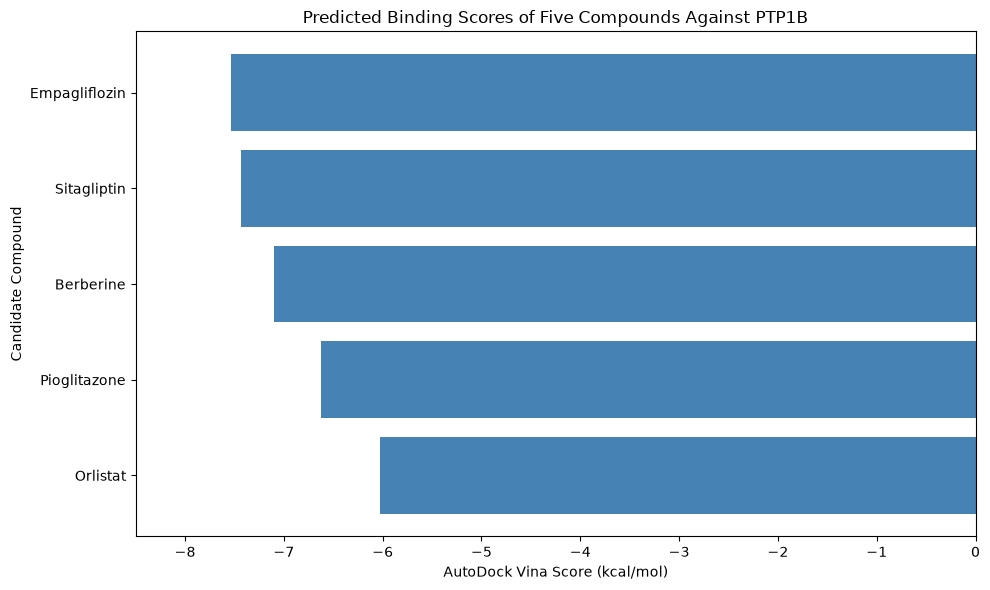

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Sort compounds by predicted binding score
plot_df = screening_df.sort_values(
    "Best_Binding_Energy_kcal_mol"
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    plot_df["Compound"],
    plot_df["Best_Binding_Energy_kcal_mol"],
    color="steelblue"
)

# Add scores to the bars
for bar in bars:
    score = bar.get_width()
    ax.text(
        score - 0.08,
        bar.get_y() + bar.get_height()/2,
        f"{score:.3f}",
        va="center",
        ha="right",
        color="white",
        fontsize=10
    )

ax.set_xlim(-8.5, 0)
ax.set_xlabel("AutoDock Vina Score (kcal/mol)")
ax.set_ylabel("Candidate Compound")
ax.set_title(
    "Predicted Binding Scores of Five Compounds Against PTP1B"
)

ax.invert_yaxis()

plt.tight_layout()

# Save figure
figures_dir = project_dir / "figures"
figures_dir.mkdir(exist_ok=True)

plt.savefig(
    figures_dir / "PCOS_docking_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
print(
    screening_df[
        ["Compound", "Best_Binding_Energy_kcal_mol",
         "Number_of_Poses", "Rank"]
    ].to_string(index=False)
)

print("\nMissing values:")
print(screening_df.isna().sum())

     Compound  Best_Binding_Energy_kcal_mol  Number_of_Poses  Rank
Empagliflozin                        -7.535                9     1
  Sitagliptin                        -7.432                9     2
    Berberine                        -7.104                9     3
 Pioglitazone                        -6.627                9     4
     Orlistat                        -6.026                9     5

Missing values:
Compound                        0
Best_Binding_Energy_kcal_mol    0
Number_of_Poses                 0
Rank                            0
dtype: int64


In [13]:
import numpy as np
import pandas as pd
from rdkit import Chem
from Bio.PDB import PDBParser
from scipy.spatial.distance import cdist

# Load your prepared protein
parser = PDBParser(QUIET=True)

protein = parser.get_structure(
    "PTP1B",
    str(docking_dir / "PTP1B_no_ASP284.pdb")
)

interaction_results = []

for drug in compounds:

    sdf_path = ligand_dir / f"{drug.lower()}_docked.sdf"

    # Read docked poses
    supplier = Chem.SDMolSupplier(
        str(sdf_path),
        removeHs=False
    )

    poses = [m for m in supplier if m is not None]

    if not poses:
        raise ValueError(f"No valid docking poses for {drug}")

    # Analyze the top-ranked pose
    best_pose = poses[0]
    conf = best_pose.GetConformer()

    ligand_coords = np.array([
        list(conf.GetAtomPosition(atom.GetIdx()))
        for atom in best_pose.GetAtoms()
        if atom.GetAtomicNum() > 1
    ])

    for residue in protein.get_residues():

        protein_coords = np.array([
            atom.coord
            for atom in residue.get_atoms()
            if atom.element not in ("H", "D")
        ])

        min_distance = cdist(
            protein_coords,
            ligand_coords
        ).min()

        if min_distance <= 4.0:
            interaction_results.append({
                "Compound": drug,
                "Residue": residue.resname,
                "Position": residue.id[1],
                "Min_Distance_A": round(
                    float(min_distance), 2
                )
            })

interaction_df = pd.DataFrame(interaction_results)

display(interaction_df)

,Compound,Residue,Position,Min_Distance_A
0,Empagliflozin,TYR,46,3.50
1,Empagliflozin,ASP,48,3.50
2,Empagliflozin,LYS,116,3.17
3,Empagliflozin,TRP,179,2.94
4,Empagliflozin,ASP,181,3.02
...,...,...,...,...
60,Berberine,GLY,220,3.64
61,Berberine,ARG,221,2.99
62,Berberine,GLN,262,3.55
63,Berberine,THR,263,3.89


In [14]:
# Summarize nearby residues for each compound

summary_df = (
    interaction_df
    .sort_values(["Compound", "Min_Distance_A"])
    .groupby("Compound")
    .agg(
        Number_of_Nearby_Residues=("Residue", "count"),
        Residue_Positions=(
            "Position",
            lambda x: ", ".join(map(str, x))
        )
    )
    .reset_index()
)

display(summary_df)

interaction_df.to_csv(
    results_dir / "PTP1B_compound_residue_distances.csv",
    index=False
)

summary_df.to_csv(
    results_dir / "PTP1B_interaction_summary.csv",
    index=False
)

print("Interaction analysis saved!")

,Compound,Number_of_Nearby_Residues,Residue_Positions
0,Berberine,11,"221, 181, 266, 183, 262, 217, 116, 220, 182, 2..."
1,Empagliflozin,12,"179, 183, 181, 221, 266, 116, 262, 46, 48, 182..."
2,Orlistat,19,"266, 183, 221, 216, 48, 215, 181, 217, 46, 262..."
3,Pioglitazone,12,"221, 183, 266, 216, 46, 120, 219, 217, 262, 18..."
4,Sitagliptin,11,"221, 220, 120, 46, 266, 216, 217, 262, 116, 26..."


Interaction analysis saved!


In [15]:
import pandas as pd

# Important PTP1B active-site residues
key_residues = {
    46: "TYR46",
    48: "ASP48",
    215: "CYS215",
    216: "SER216",
    220: "GLY220",
    221: "ARG221"
}

# Filter your interaction results
key_interactions = interaction_df[
    interaction_df["Position"].isin(key_residues.keys())
].copy()

key_interactions["Residue_Label"] = (
    key_interactions["Position"].map(key_residues)
)

# Create comparison table
comparison_df = key_interactions.pivot_table(
    index="Compound",
    columns="Residue_Label",
    values="Min_Distance_A",
    aggfunc="min"
)

# Keep a consistent column order
comparison_df = comparison_df.reindex(
    index=compounds,
    columns=list(key_residues.values())
)

display(comparison_df.round(2))

Residue_Label,TYR46,ASP48,CYS215,SER216,GLY220,ARG221
Compound,,,,,,
Empagliflozin,3.50,3.50,NaN,NaN,NaN,3.11
Pioglitazone,3.58,NaN,NaN,3.47,3.84,2.90
Sitagliptin,3.08,NaN,3.70,3.17,3.02,2.90
Orlistat,3.53,3.34,3.39,3.20,NaN,3.02
Berberine,NaN,NaN,3.69,NaN,3.64,2.99


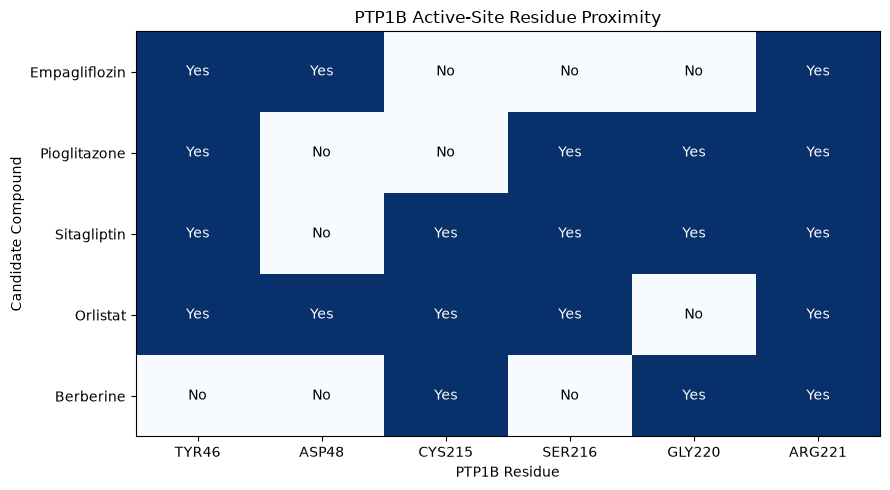

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# Convert distances to binary contacts
# 1 = residue within 4 Å; 0 = no contact within 4 Å
contact_matrix = comparison_df.notna().astype(int)

fig, ax = plt.subplots(figsize=(9, 5))

im = ax.imshow(
    contact_matrix.values,
    cmap="Blues",
    vmin=0,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(contact_matrix.columns)))
ax.set_xticklabels(contact_matrix.columns)

ax.set_yticks(range(len(contact_matrix.index)))
ax.set_yticklabels(contact_matrix.index)

ax.set_xlabel("PTP1B Residue")
ax.set_ylabel("Candidate Compound")
ax.set_title("PTP1B Active-Site Residue Proximity")

for i in range(contact_matrix.shape[0]):
    for j in range(contact_matrix.shape[1]):
        value = contact_matrix.iloc[i, j]

        ax.text(
            j, i,
            "Yes" if value == 1 else "No",
            ha="center",
            va="center",
            color="white" if value == 1 else "black"
        )

plt.tight_layout()

plt.savefig(
    figures_dir / "PTP1B_residue_contact_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# Count selected active-site residues within 4 Å
contact_counts = (
    contact_matrix.sum(axis=1)
    .rename("Key_Residues_Within_4A")
    .reset_index()
)

# Combine with docking scores
final_results = screening_df.merge(
    contact_counts,
    on="Compound",
    how="left"
)

final_results = final_results[
    [
        "Rank",
        "Compound",
        "Best_Binding_Energy_kcal_mol",
        "Key_Residues_Within_4A"
    ]
].sort_values("Rank")

display(final_results)

# Save final table
final_results.to_csv(
    results_dir / "PCOS_final_screening_summary.csv",
    index=False
)

print("Final screening summary saved!")

,Rank,Compound,Best_Binding_Energy_kcal_mol,Key_Residues_Within_4A
0,1,Empagliflozin,-7.535,3
1,2,Sitagliptin,-7.432,5
2,3,Berberine,-7.104,3
3,4,Pioglitazone,-6.627,4
4,5,Orlistat,-6.026,5


Final screening summary saved!


In [18]:
from pathlib import Path

project_dir = Path.home() / "PCOS_Drug_Repurposing"

required_files = [
    "notebooks/01_protein_preparation.ipynb",
    "notebooks/02_drug_candidate_screening.ipynb",
    "docking/PTP1B_receptor.pdbqt",
    "results/PCOS_docking_results.csv",
    "results/PCOS_final_screening_summary.csv",
    "figures/PCOS_docking_comparison.png",
    "figures/PTP1B_redocking_comparison.png",
    "figures/PTP1B_residue_contact_heatmap.png"
]

for filename in required_files:
    path = project_dir / filename
    print(
        "FOUND" if path.exists() else "MISSING",
        filename
    )

FOUND notebooks/01_protein_preparation.ipynb
FOUND notebooks/02_drug_candidate_screening.ipynb
FOUND docking/PTP1B_receptor.pdbqt
FOUND results/PCOS_docking_results.csv
FOUND results/PCOS_final_screening_summary.csv
FOUND figures/PCOS_docking_comparison.png
FOUND figures/PTP1B_redocking_comparison.png
FOUND figures/PTP1B_residue_contact_heatmap.png
